# Day 1-2

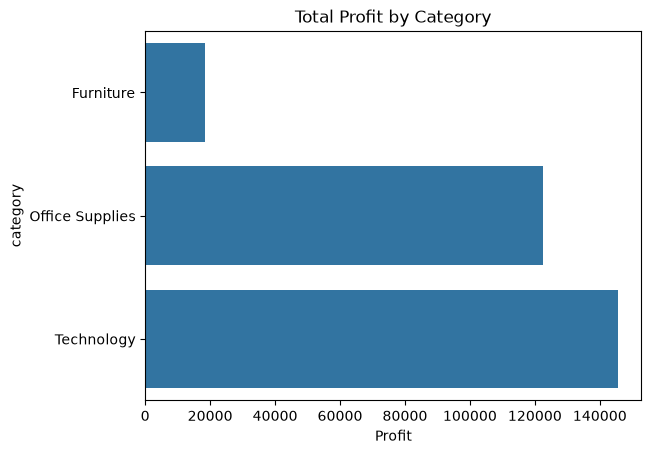

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\mraza\OneDrive\Desktop\GitHub Repositories\superstore-sales-analysis\data\superstore.csv",encoding="latin-1")
df.columns = df.columns.str.lower().str.replace(" ", "_").str.replace("-", "_")
df["order_date"] = pd.to_datetime(df["order_date"])
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.to_period("M")
df["profit_margin"] = df["profit"] / df["sales"]

cat = df.groupby("category")["profit"].sum().sort_values()
sns.barplot(x=cat.values, y=cat.index)
plt.title("Total Profit by Category")
plt.xlabel("Profit")
plt.show()


In [3]:
print("First 5 rows\n\n", df.head())
print("Info\n\n", df.info())
print(df.describe())
print(df.shape)

First 5 rows

    row_id        order_id order_date   ship_date       ship_mode customer_id  \
0       1  CA-2016-152156 2016-11-08  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11  10/18/2015  Standard Class    SO-20335   

     customer_name    segment        country             city  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

          category  sub_category  \
0        Furniture     Bookcases   
1        Fu

In [4]:
df.isnull().sum()

row_id           0
order_id         0
order_date       0
ship_date        0
ship_mode        0
customer_id      0
customer_name    0
segment          0
country          0
city             0
state            0
postal_code      0
region           0
product_id       0
category         0
sub_category     0
product_name     0
sales            0
quantity         0
discount         0
profit           0
year             0
month            0
profit_margin    0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
import re

df.columns = [
    re.sub(r"[^a-z0-9]+", "_", col.strip().lower()).strip("_")
    for col in df.columns
]

df.to_csv(r"C:\Users\mraza\OneDrive\Desktop\GitHub Repositories\superstore-sales-analysis\data\superstore.csv", index=False)

In [7]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

In [8]:
print(df.dtypes)

row_id                    int64
order_id                    str
order_date       datetime64[us]
ship_date        datetime64[us]
ship_mode                   str
customer_id                 str
customer_name               str
segment                     str
country                     str
city                        str
state                       str
postal_code               int64
region                      str
product_id                  str
category                    str
sub_category                str
product_name                str
sales                   float64
quantity                  int64
discount                float64
profit                  float64
year                      int32
month                 period[M]
profit_margin           float64
dtype: object


In [9]:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.to_period("M")
df["profit_margin"] = df["profit"] / df["sales"]

In [10]:
df[["order_date", "year", "month", "profit", "sales", "profit_margin"]].head()

,order_date,year,month,profit,sales,profit_margin
0,2016-11-08,2016,2016-11,41.9136,261.9600,0.1600
1,2016-11-08,2016,2016-11,219.5820,731.9400,0.3000
2,2016-06-12,2016,2016-06,6.8714,14.6200,0.4700
3,2015-10-11,2015,2015-10,-383.0310,957.5775,-0.4000
4,2015-10-11,2015,2015-10,2.5164,22.3680,0.1125


# Day 3-4

### Question 1: Category and Sub-category Performance

**Findings:**

- Technology generated the highest sales ($836,154.03) and profit ($145,454.95) among all three categories.
- Furniture generated $741,999.80 in sales but only $18,451.27 in profit.
- Phones had the highest sales among sub-categories, totaling $330,007.05.
- Copiers generated the highest sub-category profit, totaling $55,617.82.

**Conclusion:**

Technology is the strongest-performing category in terms of both sales and profit. However, Phones and Copiers perform differently, showing that the sub-category generating the most sales does not necessarily generate the most profit.

In [11]:
# Category Analysis
category_analysis = df.groupby("category").agg({
    "sales": "sum",
    "profit": "sum"
})

# Sub-category Analysis
subcategory_analysis = df.groupby("sub_category").agg({
    "sales": "sum",
    "profit": "sum"
})

print("CATEGORIES — Sorted by Sales")
display(category_analysis.sort_values("sales", ascending=False))

print("CATEGORIES — Sorted by Profit")
display(category_analysis.sort_values("profit", ascending=False))

print("SUB-CATEGORIES — Sorted by Sales")
display(subcategory_analysis.sort_values("sales", ascending=False))

print("SUB-CATEGORIES — Sorted by Profit")
display(subcategory_analysis.sort_values("profit", ascending=False))

CATEGORIES — Sorted by Sales


,sales,profit
category,,
Technology,836154.0330,145454.9481
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008


CATEGORIES — Sorted by Profit


,sales,profit
category,,
Technology,836154.0330,145454.9481
Office Supplies,719047.0320,122490.8008
Furniture,741999.7953,18451.2728


SUB-CATEGORIES — Sorted by Sales


,sales,profit
sub_category,,
Phones,330007.0540,44515.7306
Chairs,328449.1030,26590.1663
Storage,223843.6080,21278.8264
Tables,206965.5320,-17725.4811
Binders,203412.7330,30221.7633
Machines,189238.6310,3384.7569
Accessories,167380.3180,41936.6357
Copiers,149528.0300,55617.8249
Bookcases,114879.9963,-3472.5560


SUB-CATEGORIES — Sorted by Profit


,sales,profit
sub_category,,
Copiers,149528.0300,55617.8249
Phones,330007.0540,44515.7306
Accessories,167380.3180,41936.6357
Paper,78479.2060,34053.5693
Binders,203412.7330,30221.7633
Chairs,328449.1030,26590.1663
Storage,223843.6080,21278.8264
Appliances,107532.1610,18138.0054
Furnishings,91705.1640,13059.1436


### Question 2: Loss-Making Products and Sub-Categories

**Findings:**

- Tables recorded the largest sub-category loss, totaling -$17,725.48.
- Bookcases generated a loss of $3,472.56.
- Supplies generated a loss of $1,189.10.
- A total of 301 individual products had negative overall profit.
- The Cubify CubeX 3D Printer Double Head Print had the largest product-level loss, totaling $8,879.97.

**Conclusion:**

Tables, Bookcases, and Supplies are the three sub-categories
operating at an overall loss. The company should investigate
product pricing, discounts, and costs to understand why
these products are unprofitable.

In [12]:
# Analyze profit by sub-category
subcategory_analysis = df.groupby("sub_category").agg({
    "sales": "sum",
    "profit": "sum"
})

# Filter sub-categories with negative profit
loss_subcategories = subcategory_analysis[
    subcategory_analysis["profit"] < 0
].sort_values(by="profit")

# Analyze profit by individual product
product_analysis = df.groupby("product_name").agg({
    "sales": "sum",
    "profit": "sum"
})

# Filter loss-making products
loss_products = product_analysis[
    product_analysis["profit"] < 0
].sort_values(by="profit")

print("Loss-Making Sub-Categories:")
display(loss_subcategories.round(2))

print("Top 10 Loss-Making Products:")
display(loss_products.head(10).round(2))

print("Total Loss-Making Products:", len(loss_products))

Loss-Making Sub-Categories:


,sales,profit
sub_category,,
Tables,206965.53,-17725.48
Bookcases,114880.00,-3472.56
Supplies,46673.54,-1189.10


Top 10 Loss-Making Products:


,sales,profit
product_name,,
Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97
Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97
Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.64,-2876.12
Bush Advantage Collection Racetrack Conference Table,9544.72,-1934.40
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08
Martin Yale Chadless Opener Electric Letter Opener,16656.20,-1299.18
Balt Solid Wood Round Tables,6518.75,-1201.06


Total Loss-Making Products: 301


### Question 3: Monthly and Yearly Sales Trends

**Findings:**

- Yearly sales increased from $484,247.50 in 2014 to $733,215.26 in 2017.
- 2015 experienced a slight decline in sales, but revenue increased significantly in 2016 and 2017.
- November 2017 recorded the highest monthly sales, totaling $118,447.83.
- February 2014 recorded the lowest monthly sales, totaling $4,519.89.
- November had the highest average sales across calendar months, while February had the lowest.

**Conclusion:**

The business experienced overall sales growth between 2014 and 2017. Sales also appear to have seasonal patterns, with September, November, and December generally performing better than February. This suggests that customer demand may increase toward the end of the year.

In [13]:
# Monthly Sales Trends
monthly_sales = df.groupby("month")["sales"].sum()

# Yearly Sales Trends
yearly_sales = df.groupby("year")["sales"].sum()

# Sales by calendar month, averaged across all years
sales_by_year_month = df.groupby(
    [df["order_date"].dt.year, df["order_date"].dt.month]
)["sales"].sum()

seasonal_sales = sales_by_year_month.groupby(level=1).mean()

# Rename month numbers to month names
seasonal_sales.index = seasonal_sales.index.map(
    lambda m: pd.Timestamp(2000, m, 1).strftime("%B")
)

print("MONTHLY SALES")
display(monthly_sales.to_frame("total_sales").round(2))

print("YEARLY SALES")
display(yearly_sales.to_frame("total_sales").round(2))

print("AVERAGE SALES BY CALENDAR MONTH (SEASONALITY)")
display(seasonal_sales.to_frame("average_sales").round(2))

print("Highest Sales Year:", yearly_sales.idxmax())
print("Lowest Sales Year:", yearly_sales.idxmin())

print("Highest Sales Month:", monthly_sales.idxmax())
print("Lowest Sales Month:", monthly_sales.idxmin())

MONTHLY SALES


,total_sales
month,
2014-01,14236.90
2014-02,4519.89
2014-03,55691.01
2014-04,28295.34
2014-05,23648.29
2014-06,34595.13
2014-07,33946.39
2014-08,27909.47
2014-09,81777.35


YEARLY SALES


,total_sales
year,
2014,484247.50
2015,470532.51
2016,609205.60
2017,733215.26


AVERAGE SALES BY CALENDAR MONTH (SEASONALITY)


,average_sales
order_date,
January,23731.21
February,14937.81
March,51251.37
April,34440.53
May,38757.20
June,38179.67
July,36809.52
August,39761.02
September,76912.49


Highest Sales Year: 2017
Lowest Sales Year: 2015
Highest Sales Month: 2017-11
Lowest Sales Month: 2014-02


### Question 4: Regional Sales and Profit Performance

**Findings:**

- The West region generated the highest sales, totaling $725,457.82.
- The West region also generated the highest profit, totaling $108,418.45.
- The South region had the lowest sales, totaling $391,721.91.
- The Central region generated the lowest profit, totaling $39,706.36.
- The East region ranked second in both sales and profit.

**Conclusion:**

The West region is the strongest performer in terms of both
sales and profit. The South region needs improvement in sales,
while the Central region needs attention regarding profitability.
The company should investigate regional differences in pricing,
discounts, and product demand.

In [14]:
# Analyze Sales and Profit by Region
region_analysis = df.groupby("region").agg({
    "sales": "sum",
    "profit": "sum"
})

# Sort by Sales and Profit
print("REGIONS SORTED BY SALES")
display(region_analysis.sort_values("sales", ascending=False).round(2))

print("REGIONS SORTED BY PROFIT")
display(region_analysis.sort_values("profit", ascending=False).round(2))

# Identify Best and Worst Regions
print("Highest Sales:", region_analysis["sales"].idxmax())
print("Lowest Sales:", region_analysis["sales"].idxmin())

print("Highest Profit:", region_analysis["profit"].idxmax())
print("Lowest Profit:", region_analysis["profit"].idxmin())

REGIONS SORTED BY SALES


,sales,profit
region,,
West,725457.82,108418.45
East,678781.24,91522.78
Central,501239.89,39706.36
South,391721.90,46749.43


REGIONS SORTED BY PROFIT


,sales,profit
region,,
West,725457.82,108418.45
East,678781.24,91522.78
South,391721.90,46749.43
Central,501239.89,39706.36


Highest Sales: West
Lowest Sales: South
Highest Profit: West
Lowest Profit: Central


### Question 5: Discount Level and Profit Analysis

**Findings:**

- Orders with no discounts generated the highest total profit, approximately $320,987.60.
- Discounts between 11-20% generated approximately $91,756.30 in profit.
- Discounts between 21-30% resulted in a loss of approximately $10,369.28.
- Discounts between 31-40% resulted in a loss of approximately $25,448.19.
- Discounts above 40% resulted in the largest overall loss, approximately $99,558.59.

**Conclusion:**

The analysis shows a negative relationship between higher discount levels and profitability. Discount levels above 20% resulted in negative total profit across their respective groups. The company should carefully evaluate its discounting strategy to avoid reducing profitability.

In [15]:
# Create Discount Levels
df["discount_level"] = pd.cut(
    df["discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.40, 1],
    labels=["0%", "1-10%", "11-20%", "21-30%", "31-40%", "Above 40%"]
)

# Analyze Profit by Discount Level
discount_analysis = df.groupby(
    "discount_level", observed=True
).agg({
    "sales": "sum",
    "profit": "sum",
    "discount": "mean"
})

# Calculate Profit Margin
discount_analysis["profit_margin"] = (
    discount_analysis["profit"] / discount_analysis["sales"] * 100
)

# Display Results
display(discount_analysis.round(2).sort_values("discount"))

,sales,profit,discount,profit_margin
discount_level,,,,
0%,1087908.47,320987.60,0.00,29.51
1-10%,54369.35,9029.18,0.10,16.61
11-20%,792152.89,91756.30,0.20,11.58
21-30%,103226.66,-10369.28,0.30,-10.05
31-40%,130911.24,-25448.19,0.39,-19.44
Above 40%,128632.25,-99558.59,0.70,-77.40


### Question 5: Discount Level and Profit Analysis

**Findings:**

- Orders with no discounts generated the highest total profit, approximately $320,987.60.
- Discounts between 11-20% generated approximately $91,756.30 in profit.
- Discounts between 21-30% resulted in a loss of approximately $10,369.28.
- Discounts between 31-40% resulted in a loss of approximately $25,448.19.
- Discounts above 40% resulted in the largest overall loss, approximately $99,558.59.

**Conclusion:**

The analysis shows a negative relationship between higher discount levels and profitability. Discount levels above 20% resulted in negative total profit across their respective groups. The company should carefully evaluate its discounting strategy to avoid reducing profitability.

In [16]:
# Create Discount Levels
df["discount_level"] = pd.cut(
    df["discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.40, 1],
    labels=["0%", "1-10%", "11-20%", "21-30%", "31-40%", "Above 40%"]
)

# Analyze Profit by Discount Level
discount_analysis = df.groupby(
    "discount_level", observed=True
).agg({
    "sales": "sum",
    "profit": "sum",
    "discount": "mean"
})

# Calculate Profit Margin
discount_analysis["profit_margin"] = (
    discount_analysis["profit"] / discount_analysis["sales"] * 100
)

# Display Results
display(discount_analysis.round(2).sort_values("discount"))

,sales,profit,discount,profit_margin
discount_level,,,,
0%,1087908.47,320987.60,0.00,29.51
1-10%,54369.35,9029.18,0.10,16.61
11-20%,792152.89,91756.30,0.20,11.58
21-30%,103226.66,-10369.28,0.30,-10.05
31-40%,130911.24,-25448.19,0.39,-19.44
Above 40%,128632.25,-99558.59,0.70,-77.40


### Question 6: Top 10 Customers by Sales and Profit

**Findings:**

- Sean Miller generated the highest total sales, totaling $25,043.05.
- Tamara Chand generated the highest total profit, totaling $8,981.32.
- Sean Miller had negative total profit of $1,980.74 despite having the highest sales.
- Raymond Buch ranked among the top customers in both sales and profit.
- Six customers appeared in both the top 10 sales and top 10 profit rankings.

**Conclusion:**

The analysis shows that customers generating the
highest sales do not necessarily generate the highest
profit. The company should focus on maintaining
relationships with highly profitable customers while
investigating why some high-revenue customers generate
low or negative profit.

In [17]:
# Analyze Sales and Profit by Customer
customer_analysis = df.groupby("customer_name").agg({
    "sales": "sum",
    "profit": "sum"
})

# Top 10 Customers by Sales
top_10_sales = customer_analysis.sort_values(
    by="sales", ascending=False
).head(10)

# Top 10 Customers by Profit
top_10_profit = customer_analysis.sort_values(
    by="profit", ascending=False
).head(10)

print("TOP 10 CUSTOMERS BY SALES")
display(top_10_sales.round(2))

print("TOP 10 CUSTOMERS BY PROFIT")
display(top_10_profit.round(2))

TOP 10 CUSTOMERS BY SALES


,sales,profit
customer_name,,
Sean Miller,25043.05,-1980.74
Tamara Chand,19052.22,8981.32
Raymond Buch,15117.34,6976.10
Tom Ashbrook,14595.62,4703.79
Adrian Barton,14473.57,5444.81
Ken Lonsdale,14175.23,806.86
Sanjit Chand,14142.33,5757.41
Hunter Lopez,12873.30,5622.43
Sanjit Engle,12209.44,2650.68


TOP 10 CUSTOMERS BY PROFIT


,sales,profit
customer_name,,
Tamara Chand,19052.22,8981.32
Raymond Buch,15117.34,6976.10
Sanjit Chand,14142.33,5757.41
Hunter Lopez,12873.30,5622.43
Adrian Barton,14473.57,5444.81
Tom Ashbrook,14595.62,4703.79
Christopher Martinez,8954.02,3899.89
Keith Dawkins,8181.26,3038.63
Andy Reiter,6608.45,2884.62


### Question 7: Customer Segment Analysis

**Findings:**

- Consumer generated the highest sales, totaling $1,161,401.34.
- Consumer also generated the highest profit, totaling $134,119.21.
- Corporate generated $706,146.37 in sales and $91,979.13 in profit.
- Home Office generated $429,653.15 in sales and $60,298.68 in profit.
- Home Office had the highest profit margin at approximately 14.03%.
- Corporate had a profit margin of approximately 13.03%, while Consumer had approximately 11.55%.

**Conclusion:**

The Consumer segment is the most valuable in terms of
total sales and total profit. However, Home Office has
the highest profit margin, meaning it retains a larger
percentage of its sales as profit.

The company should continue targeting Consumer customers
while exploring opportunities to grow the more profitable
Home Office segment.

In [18]:
# Analyze Sales and Profit by Customer Segment
segment_analysis = df.groupby("segment").agg({
    "sales": "sum",
    "profit": "sum",
    "quantity": "sum",
    "customer_id": "nunique",
    "order_id": "nunique"
})

# Calculate Profit Margin
segment_analysis["profit_margin"] = (
    segment_analysis["profit"] / segment_analysis["sales"] * 100
)

# Display Results
print("CUSTOMER SEGMENT ANALYSIS")
display(segment_analysis.sort_values(
    by="profit", ascending=False
).round(2))

# Identify the Most Valuable Segments
print("Highest Sales:", segment_analysis["sales"].idxmax())
print("Highest Profit:", segment_analysis["profit"].idxmax())
print("Highest Profit Margin:", segment_analysis["profit_margin"].idxmax())

CUSTOMER SEGMENT ANALYSIS


,sales,profit,quantity,customer_id,order_id,profit_margin
segment,,,,,,
Consumer,1161401.34,134119.21,19521,409,2586,11.55
Corporate,706146.37,91979.13,11608,236,1514,13.03
Home Office,429653.15,60298.68,6744,148,909,14.03


Highest Sales: Consumer
Highest Profit: Consumer
Highest Profit Margin: Home Office


# Day 5

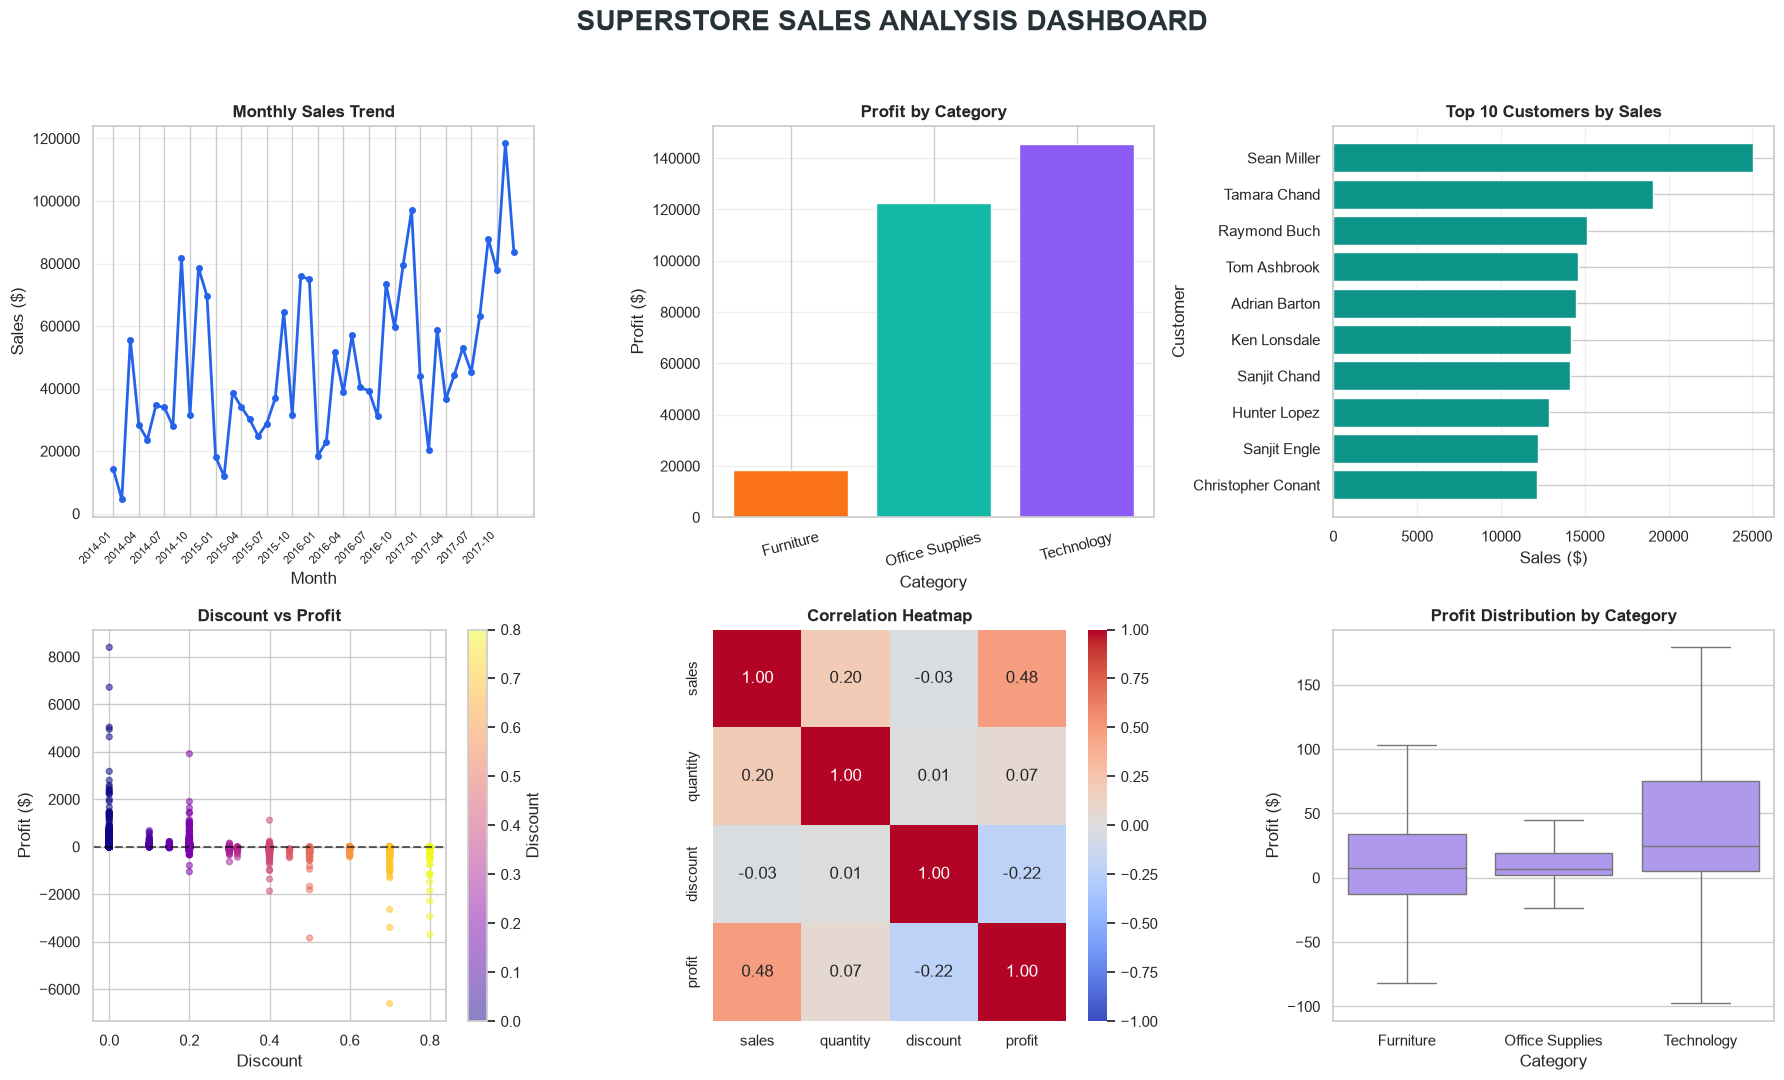

In [19]:
# Dashboard style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(18, 11))

plt.suptitle(
    "SUPERSTORE SALES ANALYSIS DASHBOARD",
    fontsize=20,
    fontweight="bold",
    color="#263238"
)


# 1. LINE CHART - Monthly Sales
monthly_sales = df.groupby("month")["sales"].sum().sort_index()

plt.subplot(2, 3, 1)
months = monthly_sales.index.astype(str)

plt.plot(
    range(len(months)),
    monthly_sales.values,
    color="#2563EB",
    marker="o",
    linewidth=2,
    markersize=4
)

plt.title("Monthly Sales Trend", fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(range(0, len(months), 3), months[::3],
           rotation=45, ha="right", fontsize=8)
plt.grid(axis="y", alpha=0.3)


# 2. BAR CHART - Profit by Category
category_profit = df.groupby("category")["profit"].sum()

plt.subplot(2, 3, 2)
plt.bar(
    category_profit.index,
    category_profit.values,
    color=["#F97316", "#14B8A6", "#8B5CF6"]
)

plt.title("Profit by Category", fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Profit ($)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)


# 3. HORIZONTAL BAR - Top 10 Customers
top_customers = df.groupby("customer_name")["sales"].sum().nlargest(10)

plt.subplot(2, 3, 3)
plt.barh(
    top_customers.sort_values().index,
    top_customers.sort_values().values,
    color="#0D9488"
)

plt.title("Top 10 Customers by Sales", fontweight="bold")
plt.xlabel("Sales ($)")
plt.ylabel("Customer")
plt.grid(axis="x", alpha=0.3)


# 4. SCATTER PLOT - Discount vs Profit
plt.subplot(2, 3, 4)

points = plt.scatter(
    df["discount"],
    df["profit"],
    c=df["discount"],
    cmap="plasma",
    alpha=0.5,
    s=18
)

plt.axhline(0, color="black", linestyle="--", alpha=0.6)
plt.colorbar(points, label="Discount")

plt.title("Discount vs Profit", fontweight="bold")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")


# 5. HEATMAP - Correlation
numeric = df[["sales", "quantity", "discount", "profit"]]

plt.subplot(2, 3, 5)

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap", fontweight="bold")


# 6. BOX PLOT - Profit by Category
plt.subplot(2, 3, 6)

sns.boxplot(
    data=df,
    x="category",
    y="profit",
    color="#A78BFA",
    showfliers=False
)

plt.title("Profit Distribution by Category", fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Profit ($)")


# Final Dashboard
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()